<a href="https://colab.research.google.com/github/Debayanpandit616/Datasciencepbl1/blob/main/EcommercecustomersegmentationNEW.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install pandas numpy matplotlib seaborn scikit-learn scipy -q

In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import KMeans

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    classification_report,
    confusion_matrix,
    silhouette_score
)

import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
from google.colab import files

uploaded = files.upload()

Saving Dataset.csv to Dataset.csv


In [4]:
df = pd.read_csv("/content/Dataset.csv")

print("Dataset loaded successfully!")

print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (9551, 21)


,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


In [5]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe(include="all").T)

Number of Rows: 9551
Number of Columns: 21

Column Names:
['Restaurant ID', 'Restaurant Name', 'Country Code', 'City', 'Address', 'Locality', 'Locality Verbose', 'Longitude', 'Latitude', 'Cuisines', 'Average Cost for two', 'Currency', 'Has Table booking', 'Has Online delivery', 'Is delivering now', 'Switch to order menu', 'Price range', 'Aggregate rating', 'Rating color', 'Rating text', 'Votes']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9551 entries, 0 to 9550
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Restaurant ID         9551 non-null   int64  
 1   Restaurant Name       9551 non-null   object 
 2   Country Code          9551 non-null   int64  
 3   City                  9551 non-null   object 
 4   Address               9551 non-null   object 
 5   Locality              9551 non-null   object 
 6   Locality Verbose      9551 non-null   object 
 7   Longitud

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Restaurant ID,9551.0,NaN,NaN,NaN,9051128.349178,8791521.282104,53.0,301962.5,6004089.0,18352291.5,18500652.0
Restaurant Name,9551,7446,Cafe Coffee Day,83,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Country Code,9551.0,NaN,NaN,NaN,18.365616,56.750546,1.0,1.0,1.0,1.0,216.0
City,9551,141,New Delhi,5473,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Address,9551,8918,"Dilli Haat, INA, New Delhi",11,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Locality,9551,1208,Connaught Place,122,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Locality Verbose,9551,1265,"Connaught Place, New Delhi",122,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Longitude,9551.0,NaN,NaN,NaN,64.126574,41.467058,-157.948486,77.081343,77.191964,77.282006,174.832089
Latitude,9551.0,NaN,NaN,NaN,25.854381,11.007935,-41.330428,28.478713,28.570469,28.642758,55.97698
Cuisines,9542,1825,North Indian,936,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
print("Missing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

Missing Values:
Restaurant ID           0
Restaurant Name         0
Country Code            0
City                    0
Address                 0
Locality                0
Locality Verbose        0
Longitude               0
Latitude                0
Cuisines                9
Average Cost for two    0
Currency                0
Has Table booking       0
Has Online delivery     0
Is delivering now       0
Switch to order menu    0
Price range             0
Aggregate rating        0
Rating color            0
Rating text             0
Votes                   0
dtype: int64

Total Missing Values:
9

Duplicate Records:
0


In [7]:
# Remove duplicate records
df = df.drop_duplicates()

# Handle missing numerical values
numerical_cols = df.select_dtypes(
    include=np.number
).columns

for col in numerical_cols:
    df[col] = df[col].fillna(df[col].median())

# Handle missing categorical values
categorical_cols = df.select_dtypes(
    include="object"
).columns

for col in categorical_cols:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(
            df[col].mode()[0]
        )

print("Data cleaning completed!")

print("Remaining missing values:")
print(df.isnull().sum().sum())

print("Updated Shape:", df.shape)

Data cleaning completed!
Remaining missing values:
0
Updated Shape: (9551, 21)


In [8]:
if "visit_date" in df.columns:

    df["visit_date"] = pd.to_datetime(
        df["visit_date"],
        format="%d-%m-%Y",
        errors="coerce"
    )

    df["visit_year"] = df["visit_date"].dt.year
    df["visit_month"] = df["visit_date"].dt.month
    df["visit_day"] = df["visit_date"].dt.day
    df["visit_weekday"] = df["visit_date"].dt.dayofweek

# Encode session duration buckets
if "session_duration_bucket" in df.columns:

    duration_mapping = {
        "Short": 0,
        "Medium": 1,
        "Long": 2
    }

    df["session_duration_bucket"] = (
        df["session_duration_bucket"]
        .astype(str)
        .str.strip()
        .str.title()
        .map(duration_mapping)
    )

print("Date and duration preprocessing completed!")

df.head()

Date and duration preprocessing completed!


,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


In [9]:
df_encoded = df.copy()

label_encoders = {}

for col in df_encoded.select_dtypes(
    include="object"
).columns:

    le = LabelEncoder()

    df_encoded[col] = le.fit_transform(
        df_encoded[col].astype(str)
    )

    label_encoders[col] = le

print("Categorical encoding completed!")

df_encoded.head()

Categorical encoding completed!


,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,3748,162,73,8685,171,172,121.027535,14.565443,920,...,0,1,0,0,0,3,4.8,0,1,314
1,6304287,3172,162,73,6055,593,601,121.014101,14.553708,1111,...,0,1,0,0,0,3,4.5,0,1,591
2,6300002,2896,162,75,4684,308,314,121.056831,14.581404,1671,...,0,1,0,0,0,4,4.4,1,5,270
3,6318506,4707,162,75,8690,862,875,121.056475,14.585318,1126,...,0,0,0,0,0,4,4.9,0,1,365
4,6314302,5523,162,75,8689,862,875,121.057508,14.584450,1122,...,0,1,0,0,0,4,4.8,0,1,229


In [10]:
if "age" in df.columns:

    plt.figure(figsize=(8, 5))

    sns.histplot(
        df["age"],
        bins=20,
        kde=True
    )

    plt.title("Customer Age Distribution")
    plt.xlabel("Age")
    plt.ylabel("Number of Customers")

    plt.show()

In [11]:
if "gender" in df.columns:

    plt.figure(figsize=(7, 5))

    sns.countplot(
        data=df,
        x="gender"
    )

    plt.title("Customer Gender Distribution")
    plt.xlabel("Gender")
    plt.ylabel("Count")

    plt.show()

In [13]:
if "product_category" in df.columns:

    plt.figure(figsize=(10, 5))

    df["product_category"].value_counts().plot(
        kind="bar"
    )

    plt.title("Popular Product Categories")
    plt.xlabel("Product Category")
    plt.ylabel("Number of Records")

    plt.xticks(rotation=45)

    plt.show()

In [14]:
if "total_purchase" in df.columns:

    plt.figure(figsize=(8, 5))

    sns.histplot(
        df["total_purchase"],
        bins=30,
        kde=True
    )

    plt.title("Customer Purchase Amount Distribution")
    plt.xlabel("Total Purchase Amount")
    plt.ylabel("Frequency")

    plt.show()

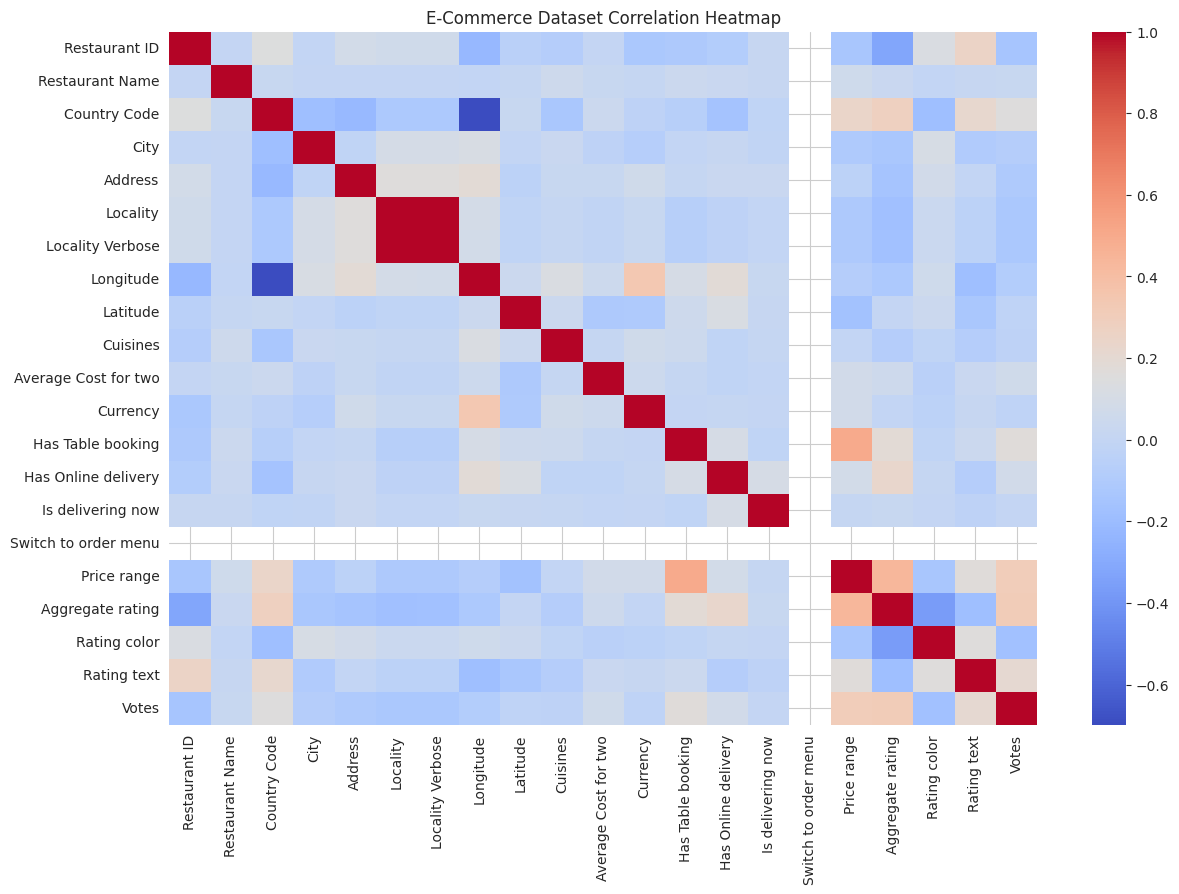

In [15]:
plt.figure(figsize=(14, 9))

correlation = df_encoded.select_dtypes(
    include=np.number
).corr()

sns.heatmap(
    correlation,
    cmap="coolwarm",
    annot=False
)

plt.title("E-Commerce Dataset Correlation Heatmap")

plt.show()

In [16]:
if "visit_month" in df.columns and "total_purchase" in df.columns:

    monthly_sales = df.groupby(
        "visit_month"
    )["total_purchase"].sum()

    plt.figure(figsize=(9, 5))

    monthly_sales.plot(
        kind="line",
        marker="o"
    )

    plt.title("Monthly Sales Trends")
    plt.xlabel("Month")
    plt.ylabel("Total Sales")

    plt.xticks(range(1, 13))

    plt.show()

In [18]:
target = "Aggregate rating"

if target not in df_encoded.columns:
    raise ValueError(
        "Please identify the correct target column."
    )

# Remove identifiers and potential high-cardinality metadata
exclude_cols = [
    target,
    "Restaurant ID",
    "Restaurant Name",
    "Address",
    "Locality",
    "Locality Verbose"
]

X = df_encoded.drop(
    columns=exclude_cols,
    errors="ignore"
)

y = df_encoded[target]

# Keep only numerical features
X = X.select_dtypes(include=np.number)

# Remove infinite values
X = X.replace([np.inf, -np.inf], np.nan)

X = X.fillna(X.median())

print("Feature Shape:", X.shape)
print("Target Shape:", y.shape)

Feature Shape: (9551, 15)
Target Shape: (9551,)


In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Records:", X_train.shape[0])
print("Testing Records:", X_test.shape[0])

Training Records: 7640
Testing Records: 1911


In [20]:
linear_model = LinearRegression()

linear_model.fit(
    X_train,
    y_train
)

y_pred = linear_model.predict(X_test)

print("Linear Regression Model Trained!")

Linear Regression Model Trained!


In [21]:
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("Linear Regression Results")

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

Linear Regression Results
MAE: 0.9502546967312138
MSE: 1.2956118008713293
RMSE: 1.1382494458032164
R2 Score: 0.43077778507646747


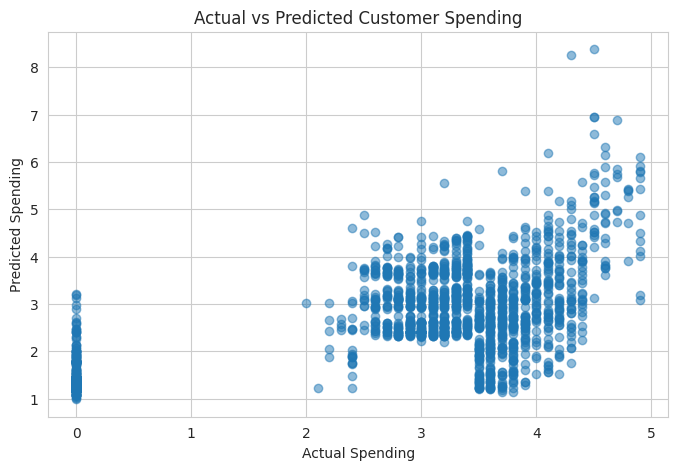

In [22]:
plt.figure(figsize=(8, 5))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.5
)

plt.xlabel("Actual Spending")
plt.ylabel("Predicted Spending")

plt.title("Actual vs Predicted Customer Spending")

plt.show()

In [24]:
# Change this to a classification target present in the dataset
purchase_target = "Has Online delivery"

if purchase_target not in df.columns:
    raise ValueError(
        f"{purchase_target} not found. Check your dataset columns."
    )

print(df[purchase_target].value_counts())

Has Online delivery
No     7100
Yes    2451
Name: count, dtype: int64


In [25]:
# Features
X_log = df_encoded.drop(
    columns=[
        purchase_target,
        "customer_id",
        "visit_date",
        "total_purchase"
    ],
    errors="ignore"
)

X_log = X_log.select_dtypes(include=np.number)

# Target
y_log = df_encoded[purchase_target]

# Ensure target is binary
if y_log.nunique() != 2:
    raise ValueError("Purchase target must contain exactly 2 classes.")

# Remove infinite values and missing values
X_log = X_log.replace([np.inf, -np.inf], np.nan)
X_log = X_log.fillna(X_log.median())

print("Features:", X_log.shape)
print("Target:", y_log.shape)

Features: (9551, 20)
Target: (9551,)


In [26]:
X_train_log, X_test_log, y_train_log, y_test_log = train_test_split(
    X_log,
    y_log,
    test_size=0.20,
    random_state=42,
    stratify=y_log
)

scaler_log = StandardScaler()

X_train_scaled = scaler_log.fit_transform(X_train_log)

X_test_scaled = scaler_log.transform(X_test_log)

print("Feature scaling completed!")

Feature scaling completed!


In [27]:
log_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

log_model.fit(
    X_train_scaled,
    y_train_log
)

log_predictions = log_model.predict(
    X_test_scaled
)

print("Logistic Regression Model Trained!")

Logistic Regression Model Trained!


In [28]:
accuracy = accuracy_score(
    y_test_log,
    log_predictions
)

print("Accuracy:", accuracy)

print("\nClassification Report:")

print(
    classification_report(
        y_test_log,
        log_predictions,
        zero_division=0
    )
)

Accuracy: 0.7571951857666144

Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.95      0.85      1421
           1       0.57      0.20      0.30       490

    accuracy                           0.76      1911
   macro avg       0.68      0.58      0.58      1911
weighted avg       0.72      0.76      0.71      1911



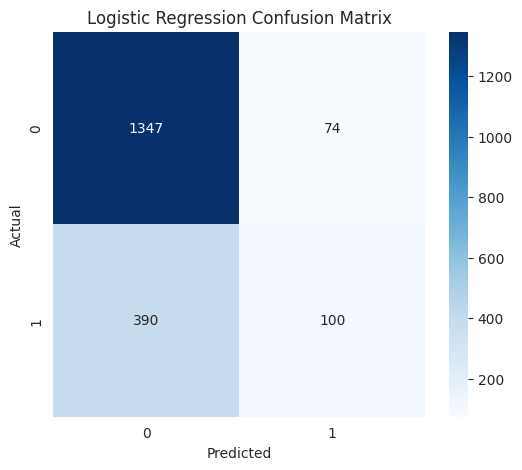

In [29]:
cm = confusion_matrix(
    y_test_log,
    log_predictions
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.title("Logistic Regression Confusion Matrix")

plt.show()

In [30]:
purchase_probability = log_model.predict_proba(
    X_test_scaled
)[:, 1]

purchase_results = pd.DataFrame({
    "Actual_Purchase": y_test_log.values,
    "Predicted_Purchase": log_predictions,
    "Purchase_Probability": purchase_probability
})

purchase_results.head(10)

,Actual_Purchase,Predicted_Purchase,Purchase_Probability
0,0,0,0.255939
1,1,0,0.409725
2,0,0,0.005823
3,0,0,0.323021
4,0,0,0.275287
5,1,0,0.087050
6,0,0,0.284499
7,0,0,0.000034
8,1,0,0.449366
9,0,0,0.433270


In [33]:
# For a content-based recommendation approach since there is no customer transaction history
# We will use features of the restaurants (Cuisines and Price range) to build a similarity profile
from sklearn.feature_extraction.text import TfidfVectorizer

# Fill missing values in cuisines if any
df['Cuisines'] = df['Cuisines'].fillna('Unknown')

# Create a TF-IDF matrix for cuisines
tfidf = TfidfVectorizer(stop_words='english')
tfidf_matrix = tfidf.fit_transform(df['Cuisines'])

print("Restaurant Cuisine TF-IDF Matrix Shape:", tfidf_matrix.shape)
print("Successfully prepared restaurant profiles for recommendation!")

Restaurant Cuisine TF-IDF Matrix Shape: (9551, 148)
Successfully prepared restaurant profiles for recommendation!


In [34]:
# Train the KNN model on the prepared TF-IDF cuisine matrix
knn_model = NearestNeighbors(
    metric="cosine",
    algorithm="brute"
)

knn_model.fit(tfidf_matrix)

# Simple helper function to recommend similar restaurants
def recommend_restaurants(restaurant_index, n_recommendations=5):
    distances, indices = knn_model.kneighbors(
        tfidf_matrix[restaurant_index],
        n_neighbors=n_recommendations + 1
    )

    print(f"Recommendations for: '{df.iloc[restaurant_index]['Restaurant Name']}' ({df.iloc[restaurant_index]['Cuisines']})\n")
    for i in range(1, len(distances.flatten())):
        rec_idx = indices.flatten()[i]
        print(f"{i}: {df.iloc[rec_idx]['Restaurant Name']} | Cuisines: {df.iloc[rec_idx]['Cuisines']} | Rating: {df.iloc[rec_idx]['Aggregate rating']}")

# Demo
recommend_restaurants(0)

Recommendations for: 'Le Petit Souffle' (French, Japanese, Desserts)

1: Tokyo Mon Amour | Cuisines: Japanese, French | Rating: 3.1
2: The French by Simon Rogan - The Midland | Cuisines: French | Rating: 4.3
3: Restaurant Gordon Ramsay | Cuisines: French | Rating: 4.7
4: Rhubarb Le Restaurant | Cuisines: French | Rating: 3.9
5: Jaan | Cuisines: French | Rating: 3.8


In [42]:
def recommend_restaurants_by_name(restaurant_name, n_recommendations=5):
    try:
        # Find the index of the restaurant by name
        restaurant_index = df[df['Restaurant Name'].str.lower() == restaurant_name.lower()].index[0]
        recommend_restaurants(restaurant_index, n_recommendations)
    except IndexError:
        print(f"Restaurant '{restaurant_name}' not found in the dataset.")

In [37]:
# Demonstrate the content-based recommendation system
# We will select the first restaurant as our sample
sample_index = 0
sample_restaurant_name = df.iloc[sample_index]['Restaurant Name']

print(f"Recommendations for restaurant at index {sample_index} ({sample_restaurant_name}):\n")
recommend_restaurants(sample_index, n_recommendations=5)

Recommendations for restaurant at index 0 (Le Petit Souffle):

Recommendations for: 'Le Petit Souffle' (French, Japanese, Desserts)

1: Tokyo Mon Amour | Cuisines: Japanese, French | Rating: 3.1
2: The French by Simon Rogan - The Midland | Cuisines: French | Rating: 4.3
3: Restaurant Gordon Ramsay | Cuisines: French | Rating: 4.7
4: Rhubarb Le Restaurant | Cuisines: French | Rating: 3.9
5: Jaan | Cuisines: French | Rating: 3.8


In [39]:
# Select numerical restaurant features for segmentation/clustering
segmentation_features = [
    col for col in [
        "Aggregate rating",
        "Votes",
        "Average Cost for two",
        "Price range"
    ]
    if col in df.columns
]

if len(segmentation_features) == 0:
    raise ValueError("No suitable restaurant features found for segmentation.")

# Prepare restaurant data for segmentation
restaurant_data = df_encoded[segmentation_features].copy()

restaurant_data = restaurant_data.replace(
    [np.inf, -np.inf],
    np.nan
)

restaurant_data = restaurant_data.fillna(
    restaurant_data.median()
)

print("Restaurant Segmentation Dataset Ready:")
display(restaurant_data.head())

Restaurant Segmentation Dataset Ready:


,Aggregate rating,Votes,Average Cost for two,Price range
0,4.8,314,1100,3
1,4.5,591,1200,3
2,4.4,270,4000,4
3,4.9,365,1500,4
4,4.8,229,1500,4


In [41]:
scaler_kmeans = StandardScaler()

restaurant_scaled = scaler_kmeans.fit_transform(
    restaurant_data
)

print("Restaurant features scaled!")

Restaurant features scaled!


In [44]:
kmeans = KMeans(n_clusters=4, random_state=42)
kmeans_labels = kmeans.fit_predict(restaurant_scaled)

restaurant_data['Cluster'] = kmeans_labels
print("K-Means clustering completed!")

sil_score = silhouette_score(restaurant_scaled, kmeans_labels)
print(f"Silhouette Score: {sil_score:.4f}")

K-Means clustering completed!
Silhouette Score: 0.4298


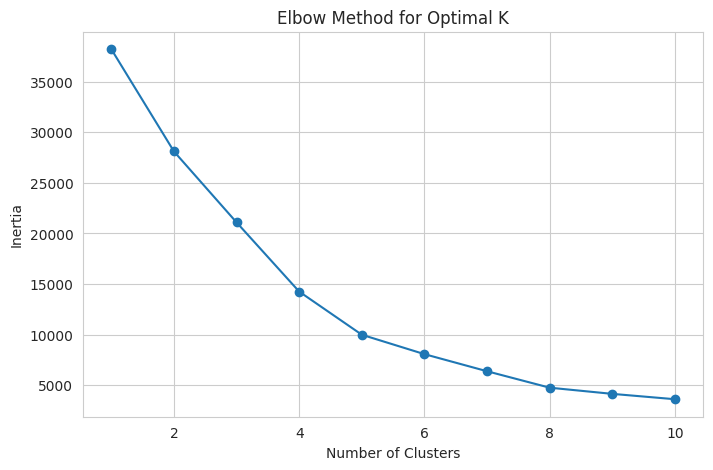

In [47]:
inertia_values = []

for k in range(1, 11):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(restaurant_scaled)

    inertia_values.append(model.inertia_)

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 11),
    inertia_values,
    marker="o"
)

plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")

plt.title("Elbow Method for Optimal K")

plt.show()

In [63]:
cluster_votes = restaurant_data.groupby('Cluster')['Votes'].mean().sort_values()

segment_mapping = {
    cluster_votes.index[0]: "Low Engagement",
    cluster_votes.index[1]: "Medium Engagement",
    cluster_votes.index[2]: "High Engagement",
    cluster_votes.index[3]: "Top Voted"
}

restaurant_data['Restaurant_Segment'] = restaurant_data['Cluster'].map(segment_mapping)
print("Restaurant Segments Created!")
display(restaurant_data.head(10))

Restaurant Segments Created!


,Aggregate rating,Votes,Average Cost for two,Price range,Cluster,Restaurant_Segment
0,4.8,314,1100,3,0,Medium Engagement
1,4.5,591,1200,3,0,Medium Engagement
2,4.4,270,4000,4,0,Medium Engagement
3,4.9,365,1500,4,0,Medium Engagement
4,4.8,229,1500,4,0,Medium Engagement
5,4.4,336,1000,3,0,Medium Engagement
6,4.0,520,2000,4,0,Medium Engagement
7,4.2,677,2000,4,0,Medium Engagement
8,4.9,621,6000,4,0,Medium Engagement
9,4.8,532,1100,3,0,Medium Engagement


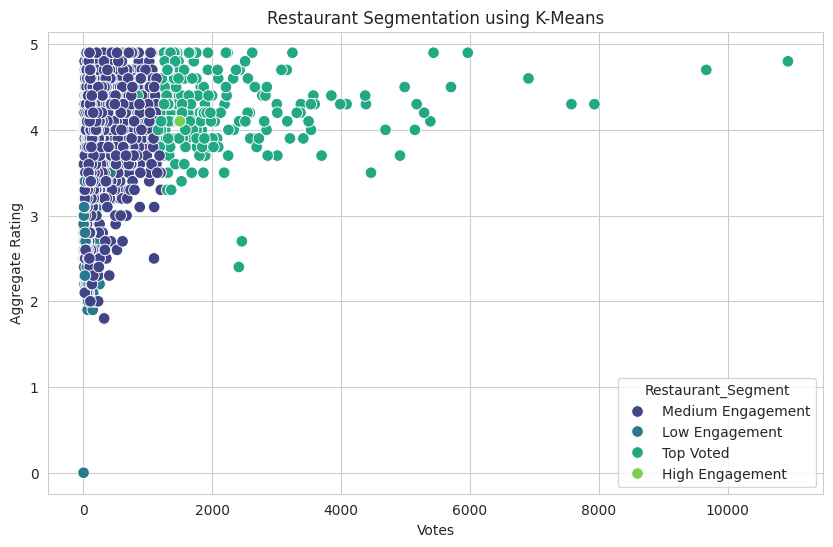

In [65]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=restaurant_data,
    x="Votes",
    y="Aggregate rating",
    hue="Restaurant_Segment",
    palette="viridis",
    s=70
)

plt.title("Restaurant Segmentation using K-Means")
plt.xlabel("Votes")
plt.ylabel("Aggregate Rating")

plt.show()

Restaurant_Segment
Low Engagement       4827
Medium Engagement    4479
Top Voted             238
High Engagement         7
Name: count, dtype: int64


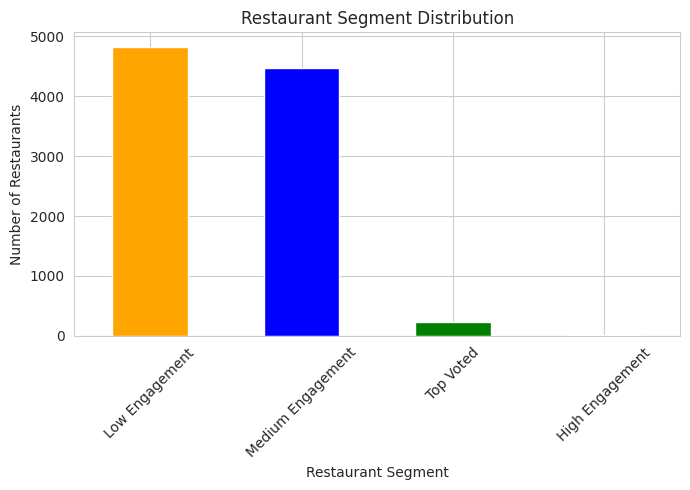

In [66]:
segment_counts = restaurant_data[
    "Restaurant_Segment"
].value_counts()

print(segment_counts)

plt.figure(figsize=(7, 5))

segment_counts.plot(
    kind="bar",
    color=["orange", "blue", "green", "red"]
)

plt.title("Restaurant Segment Distribution")

plt.xlabel("Restaurant Segment")
plt.ylabel("Number of Restaurants")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [67]:
silhouette = silhouette_score(
    restaurant_scaled,
    restaurant_data["Cluster"]
)

print("Silhouette Score:", silhouette)

Silhouette Score: 0.4297920046273505


In [52]:
cv_scores = cross_val_score(
    LinearRegression(),
    X,
    y,
    cv=5,
    scoring="r2"
)

print("Cross Validation Scores:", cv_scores)

print("Average CV Score:", cv_scores.mean())

Cross Validation Scores: [  0.12315527   0.26042797   0.41437004   0.4495543  -28.34912839]
Average CV Score: -5.420324161872094


In [53]:
cv_scores_log = cross_val_score(
    LogisticRegression(max_iter=1000),
    X_train_scaled,
    y_train_log,
    cv=5,
    scoring="accuracy"
)

print("Logistic CV Scores:", cv_scores_log)

print("Average Logistic CV Accuracy:", cv_scores_log.mean())

Logistic CV Scores: [0.74934555 0.7408377  0.7486911  0.7565445  0.7447644 ]
Average Logistic CV Accuracy: 0.7480366492146597


In [54]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "C": [0.01, 0.1, 1, 10, 100],
    "solver": ["liblinear"],
    "penalty": ["l1", "l2"]
}

grid_search = GridSearchCV(
    LogisticRegression(max_iter=1000),
    param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

grid_search.fit(
    X_train_scaled,
    y_train_log
)

print("Best Parameters:", grid_search.best_params_)

print("Best CV Accuracy:", grid_search.best_score_)

best_log_model = grid_search.best_estimator_

Best Parameters: {'C': 10, 'penalty': 'l2', 'solver': 'liblinear'}
Best CV Accuracy: 0.7526178010471205


In [55]:
optimized_predictions = best_log_model.predict(
    X_test_scaled
)

print(
    "Original Accuracy:",
    accuracy_score(y_test_log, log_predictions)
)

print(
    "Optimized Accuracy:",
    accuracy_score(y_test_log, optimized_predictions)
)

Original Accuracy: 0.7571951857666144
Optimized Accuracy: 0.7571951857666144


In [68]:
rating_results = pd.DataFrame({
    "Actual_Rating": y_test.values,
    "Predicted_Rating": y_pred
}, index=y_test.index)

rating_results.insert(
    0,
    "Restaurant_ID",
    df.loc[y_test.index, "Restaurant ID"].values
)

rating_results.to_csv(
    "predicted_restaurant_rating.csv",
    index=False
)

print("Restaurant rating prediction CSV exported!")

Restaurant rating prediction CSV exported!


In [69]:
purchase_results = pd.DataFrame({
    "Actual_Purchase": y_test_log.values,
    "Predicted_Purchase": optimized_predictions,
    "Purchase_Probability": best_log_model.predict_proba(
        X_test_scaled
    )[:, 1]
})

purchase_results.insert(
    0,
    "Restaurant_ID",
    df.loc[y_test_log.index, "Restaurant ID"].values
)

purchase_results.to_csv(
    "purchase_probability.csv",
    index=False
)

print("Purchase probability CSV exported!")

Purchase probability CSV exported!


In [70]:
restaurant_segments = restaurant_data.reset_index()

restaurant_segments.to_csv(
    "restaurant_segments.csv",
    index=False
)

print("Restaurant segmentation CSV exported!")

Restaurant segmentation CSV exported!


In [71]:
all_recommendations = []

# Generate recommendations for a subset of restaurants to keep execution quick
sample_indices = range(min(100, len(df)))

for idx in sample_indices:
    distances, indices = knn_model.kneighbors(
        tfidf_matrix[idx],
        n_neighbors=6
    )
    for rank, (dist, rec_idx) in enumerate(zip(distances.flatten()[1:], indices.flatten()[1:]), 1):
        all_recommendations.append({
            "Original_Restaurant_ID": df.iloc[idx]["Restaurant ID"],
            "Original_Restaurant_Name": df.iloc[idx]["Restaurant Name"],
            "Recommendation_Rank": rank,
            "Recommended_Restaurant_ID": df.iloc[rec_idx]["Restaurant ID"],
            "Recommended_Restaurant_Name": df.iloc[rec_idx]["Restaurant Name"],
            "Cuisine_Similarity": 1 - dist
        })

recommendations_df = pd.DataFrame(all_recommendations)
recommendations_df.to_csv("restaurant_recommendations.csv", index=False)
print("Restaurant recommendations exported!")

Restaurant recommendations exported!


In [72]:
from google.colab import files

output_files = [
    "predicted_restaurant_rating.csv",
    "purchase_probability.csv",
    "restaurant_segments.csv",
    "restaurant_recommendations.csv"
]

for file in output_files:
    files.download(file)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [73]:
model_results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Logistic Regression",
        "K-Means Clustering"
    ],

    "Performance Metric": [
        "R2 Score",
        "Accuracy",
        "Silhouette Score"
    ],

    "Score": [
        r2,
        accuracy_score(y_test_log, optimized_predictions),
        sil_score
    ]
})

display(model_results)

,Model,Performance Metric,Score
0,Linear Regression,R2 Score,0.430778
1,Logistic Regression,Accuracy,0.757195
2,K-Means Clustering,Silhouette Score,0.429792


In [74]:
print("=" * 55)
print(" ZOMATO RESTAURANT ANALYTICS - SUMMARY")
print("=" * 55)

print("\n1. DATASET")
print("Total Records:", df.shape[0])
print("Total Features:", df.shape[1])

print("\n2. LINEAR REGRESSION (RATING PREDICTION)")
print("R2 Score:", round(r2, 4))
print("RMSE:", round(rmse, 4))

print("\n3. LOGISTIC REGRESSION (ONLINE DELIVERY)")
print(
    "Accuracy:",
    round(accuracy_score(y_test_log, optimized_predictions), 4)
)

print("\n4. KNN RECOMMENDATION")
print("Total Recommendations Generated:", len(recommendations_df))

print("\n5. K-MEANS CLUSTERING")
print("Number of Clusters:", len(np.unique(kmeans_labels)))
print("Silhouette Score:", round(silhouette, 4))

print("\n6. RESTAURANT SEGMENTS")
print(restaurant_data["Restaurant_Segment"].value_counts())

print("\nPROJECT ANALYSIS COMPLETED!")

 ZOMATO RESTAURANT ANALYTICS - SUMMARY

1. DATASET
Total Records: 9551
Total Features: 21

2. LINEAR REGRESSION (RATING PREDICTION)
R2 Score: 0.4308
RMSE: 1.1382

3. LOGISTIC REGRESSION (ONLINE DELIVERY)
Accuracy: 0.7572

4. KNN RECOMMENDATION
Total Recommendations Generated: 500

5. K-MEANS CLUSTERING
Number of Clusters: 4
Silhouette Score: 0.4298

6. RESTAURANT SEGMENTS
Restaurant_Segment
Low Engagement       4827
Medium Engagement    4479
Top Voted             238
High Engagement         7
Name: count, dtype: int64

PROJECT ANALYSIS COMPLETED!
